In [3]:
import numpy as np

"""computes two roots"""
def x_plus(p, q):
    return -p + np.sqrt(p**2 + q)
def x_minus(p, q):
    return -p - np.sqrt(p**2 + q)
    
"""Computes the numerical relative sensitivity R"""
def get_R(func, p, q, dp):
    x_orig = func(p, q)
    x_pert = func(p + dp, q)
    rel_change_x = np.abs((x_pert - x_orig) / x_orig)
    rel_change_p = np.abs(dp / p)
    return rel_change_x / rel_change_p

'''computes R_plus for p=-1 and p=1'''
R_plus_1 = get_R(x_plus, -1, 1, 10**-3)
R_plus_2 = get_R(x_plus, 1, 1, 10**-3)
print(R_plus_1)
print(R_plus_2)

'''computes R_minus for p=-1 and p=1'''
R_minus_1 = get_R(x_minus, -1, 1, 10**-3)
R_minus_2 = get_R(x_minus, 1, 1, 10**-3)
print(R_minus_1)
print(R_minus_2)
    

0.7070335212563417
0.7066802177995782
0.7075337713501161
0.7071799678933286


All R smaller than 1, well-conditioned. And all these four values are roughly equal. 

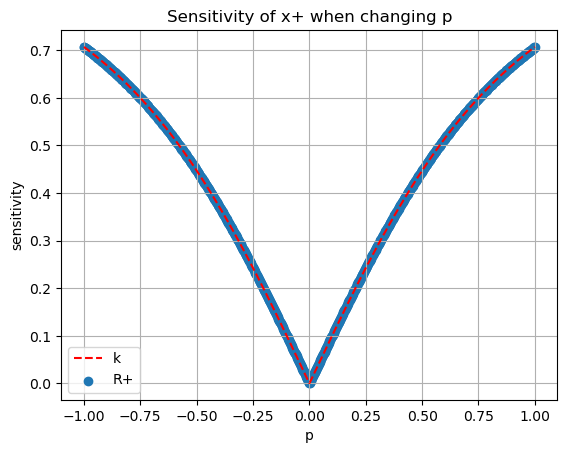

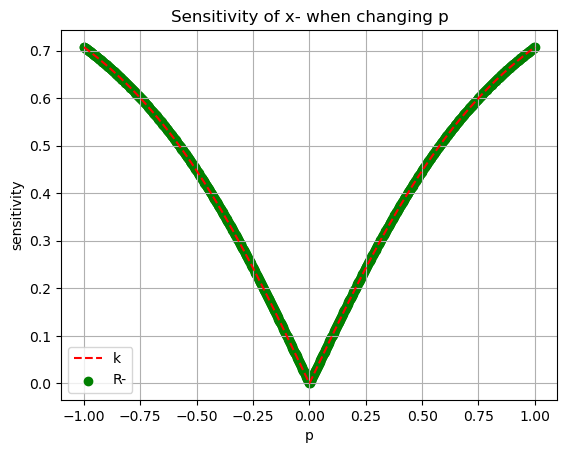

In [33]:
import matplotlib.pyplot as plt
import numpy as np
def Kp(p,q):
    k=np.abs(p/np.sqrt(p**2+q))
    return k

# Plot R+ vs p
p_range = np.linspace(-1, 1, 1000)
R_plus=get_R(x_plus, p_range, 1, 10**-3)
K=Kp(p_range,1)
plt.plot(p_range, K,color='r',linestyle='dashed',label='k')
plt.scatter(p_range, R_plus,label='R+')
plt.title('Sensitivity of x+ when changing p')
plt.xlabel('p')
plt.ylabel('sensitivity')
plt.grid(True)
plt.legend()
plt.show()

# Plot R- vs p
p_range = np.linspace(-1, 1, 1000)
R_minus=get_R(x_minus, p_range, 1, 10**-3)
K=Kp(p_range,1)
plt.plot(p_range, K,color='r',linestyle='dashed',label='k')
plt.scatter(p_range, R_minus,color='g',label='R-')
plt.title('Sensitivity of x- when changing p')
plt.xlabel('p')
plt.ylabel('sensitivity')
plt.grid(True)
plt.legend()
plt.show()


Kp, P+ and P- are roughly equal.

In [31]:
import numpy as np

"""computes two roots"""
def x_plus(p, q):
    return -p + np.sqrt(p**2 + q)
def x_minus(p, q):
    return -p - np.sqrt(p**2 + q)
    
"""Computes the numerical relative sensitivity R"""
def R(func, p, q, dq):
    x_orig = func(p, q)
    x_pert = func(p, q+dq)
    rel_change_x = np.abs((x_pert - x_orig) / x_orig)
    rel_change_q = np.abs(dq / q)
    return rel_change_x / rel_change_q

'''computes R_plus for q=-1 and q=1'''
R_plus_1 = R(x_plus, 1, 1, 10**-3)
R_plus_2 = R(x_plus, 1, -1, 10**-3)
print(R_plus_1)
print(R_plus_2)

'''computes R_minus for q=-1 and q=1'''
R_minus_1 = R(x_minus, 1, 1, 10**-3)
R_minus_2 = R(x_minus, 1, -1, 10**-3)
print(R_minus_1)
print(R_minus_2)
    



0.8534467230844732
31.62277660168378
0.1464283081556372
31.62277660168389


C:\Users\27126\AppData\Local\Temp\ipykernel_26552\4067271388.py:4: RuntimeWarning: divide by zero encountered in divide
  k=0.5*np.abs(q/(-p*np.sqrt(p**2+q)+(p**2+q)))


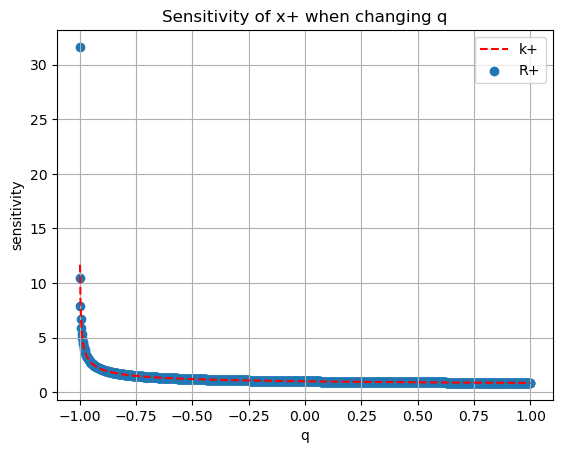

C:\Users\27126\AppData\Local\Temp\ipykernel_26552\4067271388.py:7: RuntimeWarning: divide by zero encountered in divide
  k=0.5*np.abs(q/(-p*np.sqrt(p**2+q)-(p**2+q)))


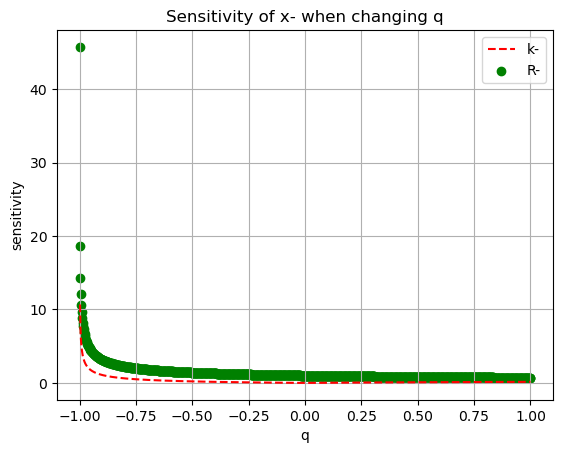

In [35]:
import matplotlib.pyplot as plt
import numpy as np
def Kq_plus(p,q):
    k=0.5*np.abs(q/(-p*np.sqrt(p**2+q)+(p**2+q)))
    return k
def Kq_minus(p,q):
    k=0.5*np.abs(q/(-p*np.sqrt(p**2+q)-(p**2+q)))
    return k

# Plot R+ vs q
q_range = np.linspace(-1, 1, 1000)
R_plus=R(x_plus, 1, q_range, 10**-3)
K_plus=Kq_plus(1,q_range)
plt.plot(q_range, K_plus,color='r',linestyle='dashed',label='k+')
plt.scatter(q_range, R_plus,label='R+')
plt.title('Sensitivity of x+ when changing q')
plt.xlabel('q')
plt.ylabel('sensitivity')
plt.grid(True)
plt.legend()
plt.show()

# Plot R- vs q
q_range = np.linspace(-1, 1, 1000)
R_minus=get_R(x_minus, 1 , q_range, 10**-3)
K_plus=Kq_minus(1,q_range)
plt.plot(q_range, K_plus,color='r',linestyle='dashed',label='k-')
plt.scatter(q_range, R_minus,color='g',label='R-')
plt.title('Sensitivity of x- when changing q')
plt.xlabel('q')
plt.ylabel('sensitivity')
plt.grid(True)
plt.legend()

R+ is roughly equal to Kq+, but R- is greater than k-.

In [6]:
import numpy as np

def f(x):
    return 2*np.sin(2*x)
    
def linear_interpolate(f, x_0, x_1, x):
    p_1_x =(x-x_1)/(x_0-x_1)*f(x_0)+ (x-x_0)/(x_1-x_0)*f(x_1)
    return p_1_x
    
print(linear_interpolate(f, 0, 1, 0.75))

1.3639461402385225


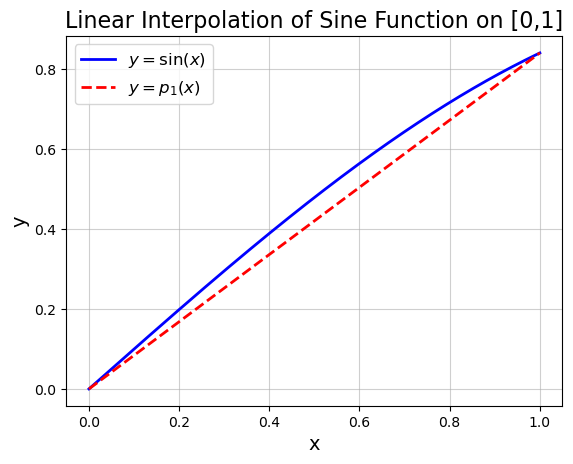

In [7]:
import matplotlib.pyplot as plt

x_0, x_1 = 0, 1
x_vals = np.linspace(x_0, x_1, 1000)
y_vals_1 = np.sin(x_vals)
y_vals_2 = [linear_interpolate(np.sin, 0, 1, x) for x in x_vals]
plt.plot(x_vals, y_vals_1, label=r'$y=\sin(x)$', color='b', linewidth=2)
plt.plot(x_vals, y_vals_2, label=r'$y=p_1(x)$', color='r', linestyle='dashed', linewidth=2)
plt.title('Linear Interpolation of Sine Function on [0,1]', fontsize=16)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.grid(True, alpha=0.6)
plt.legend(fontsize=12)
plt.show()


$p_1(x)$ shows a straight line through (0,0）and (1,sin(1)), while sin(x) is a concave
function between (0,0）and (1,sin(1)). Therefore, $p_1(x)$ underestimates sin(x) in $[0,1]$.

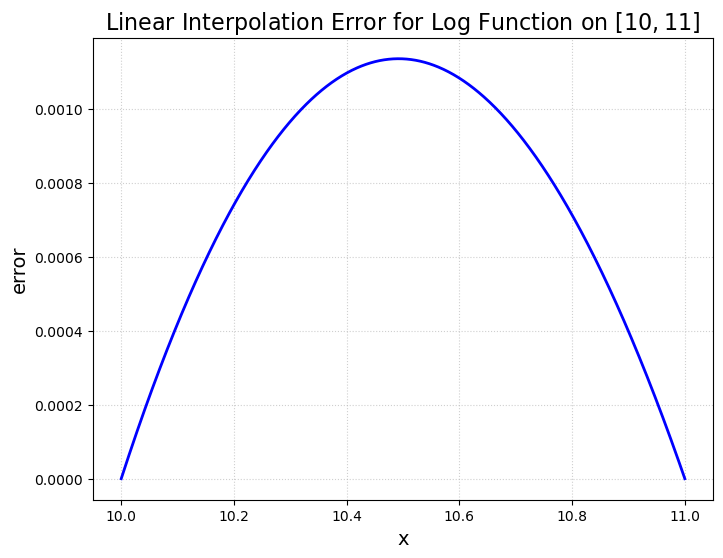

error at x=10.2 is 0.0007405913353144555
error at x=10.8 is  0.0007128972926682131


In [23]:
def interpolation_error(f, x_0, x_1, x): 
    return f(x) - linear_interpolate(f,x_0,x_1,x)

x_0, x_1 = 10, 11
x_vals = np.linspace(x_0, x_1, 1000)
y_vals = [interpolation_error(np.log, x_0, x_1, x) for x in x_vals]

# plot sin and its linear interpolant
plt.figure(figsize=(8, 6))
plt.plot(x_vals, y_vals, color='b', linewidth=2)
plt.title('Linear Interpolation Error for Log Function on $[10,11]$', fontsize=16)
plt.xlabel('x', fontsize=14)
plt.ylabel('error', fontsize=14)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

#calculate error at x=10.2 and x=10.8
error_1=interpolation_error(np.log, x_0, x_1, 10.2)
print('error at x=10.2 is', error_1)
error_2=interpolation_error(np.log, x_0, x_1, 10.8)
print('error at x=10.8 is ',error_2)



In [39]:
def max_error(f, x_0, x_1):
    x_vals = np.linspace(x_0, x_1, 1000)
    abs_error_vals = [abs(interpolation_error(f, x_0, x_1, x)) for x in x_vals]
    return np.max(abs_error_vals)

def f(x):
    return 1/(1+x**2)

# compute maximum error for h = 1
h = 1
max_err_h1 = max_error(f, 0, h)
print(f"Maximum absolute error for h = {h} is {max_err_h1}")

Maximum absolute error for h = 1 is 0.06744219634970638


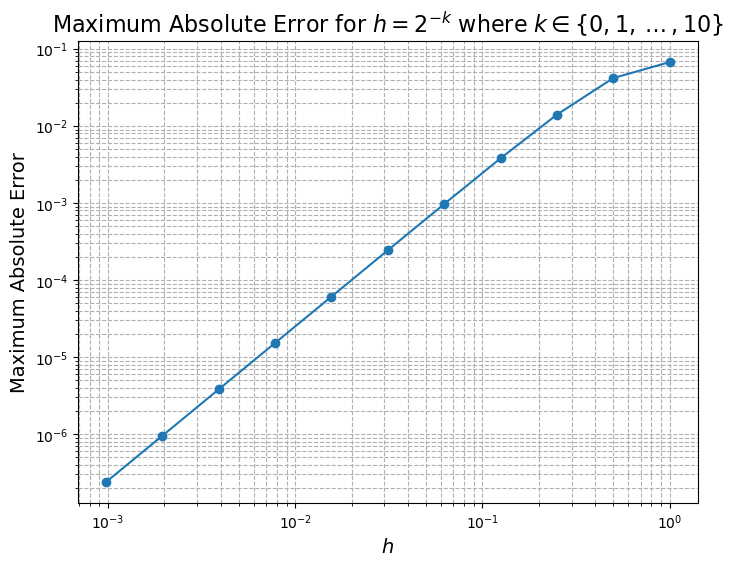

In [36]:
# compute max error for various h = 2^(-k) for k = 0, ..., 10
h_values = [2**(-k) for k in range(0,11)]
max_errors = [max_error(f, 0, h) for h in h_values]

# plot on log-log scale
plt.figure(figsize=(8, 6))
plt.loglog(h_values, max_errors, marker='o', linestyle='-')
plt.xlabel(r'$h$', fontsize=14)
plt.ylabel(r'Maximum Absolute Error', fontsize=14)
plt.title(r'Maximum Absolute Error for $h=2^{-k}$ where $k\in \{0,1, \dots, 10\}$', fontsize=16)
plt.grid(True, which='both',linestyle='dashed')
plt.show()

Linear relationship between Maximum Absolute Error and h as plotted in log-log scale.

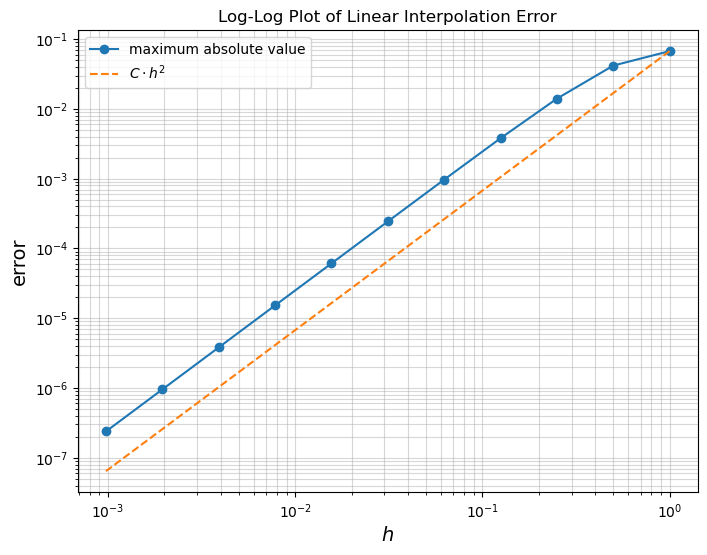

In [62]:
# compute max error for various h = 2^(-k) for k = 0, ..., 10
h_values = [2**(-k) for k in range(0,11)]
max_errors = [max_error(f, 0, h) for h in h_values]
gamma = 2
scaling = max_errors[0] / (h_values[0]**gamma)

# plot on log-log scale
plt.figure(figsize=(8, 6))
plt.loglog(h_values, max_errors, marker='o', linestyle='-',label='maximum absolute value')
plt.loglog(h_values, scaling * np.array(h_values)**gamma, '--', label=r'$C \cdot h^2$')
plt.xlabel(r'$h$', fontsize=14)
plt.ylabel(r'error', fontsize=14)
plt.grid(True, which='both',linestyle='dashed')
plt.title('Log-Log Plot of Linear Interpolation Error')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

Gamma = 2. The slope of the line is approximately 2.This indicates that the error behaves as $E(h) \approx Ch^2$. 

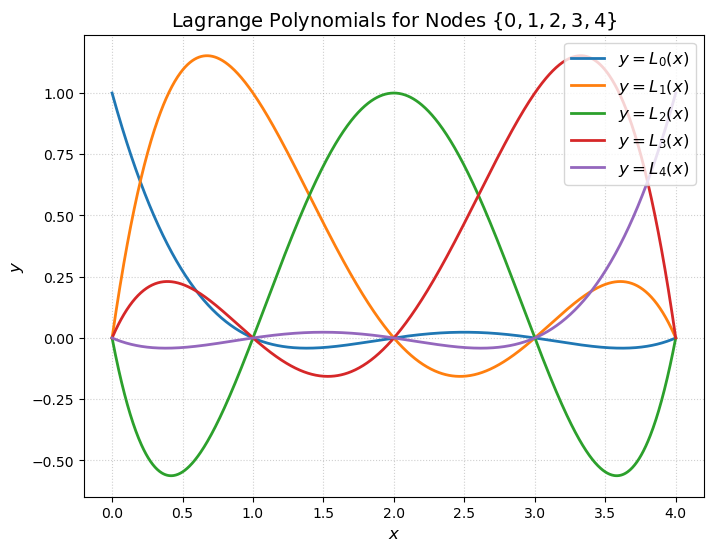

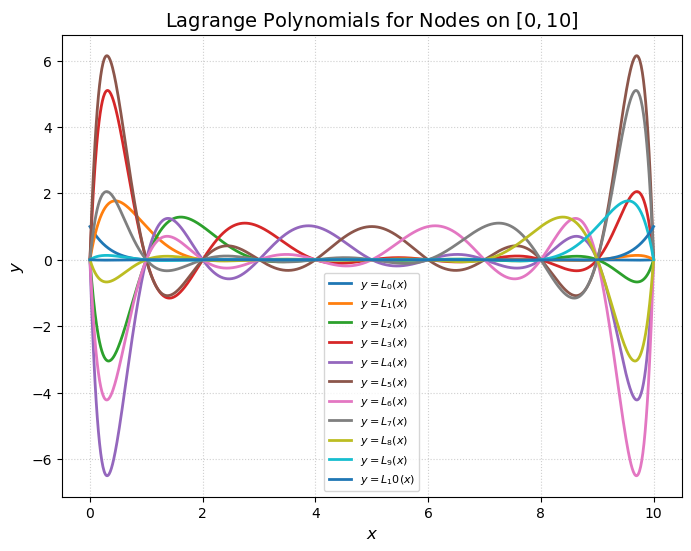

In [74]:
def lagrange(k, x, nodes): 
    L_k = np.ones_like(x, dtype=float) 
    for j in range(len(nodes)): 
        if j != k:
            L_k *= (x - nodes[j]) / (nodes[k] - nodes[j]) 
    return L_k
    
nodes = [0,1,2,3,4]
x = np.linspace(0,4,1000)
plt.figure(figsize=(8, 6))
for k in nodes:
    y = lagrange(k, x, nodes)
    plt.plot(x, y, label=rf'$y=L_{k}(x)$', linewidth=2)
plt.title(r'Lagrange Polynomials for Nodes $\{0,1,2,3,4\}$', fontsize=14)
plt.xlabel(r'$x$', fontsize=12)
plt.ylabel(r'$y$', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=12)
plt.show()

nodes = np.arange(11)
x = np.linspace(0,10,1000)
plt.figure(figsize=(8, 6))
for k in nodes:
    y = lagrange(k, x, nodes)
    plt.plot(x, y, label=rf'$y=L_{k}(x)$', linewidth=2)
plt.title(r'Lagrange Polynomials for Nodes on $[0,10]$', fontsize=14)
plt.xlabel(r'$x$', fontsize=12)
plt.ylabel(r'$y$', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=8)
plt.show()

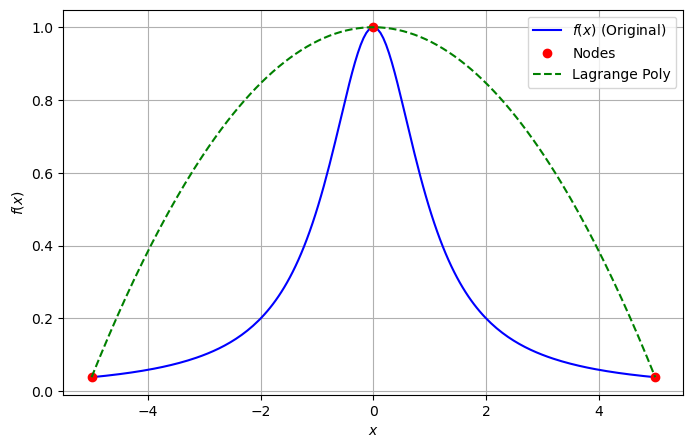

Lagrange Poly at x=1 is 0.9615384615384615
Lagrange Poly at x=4.5 is 0.22115384615384615


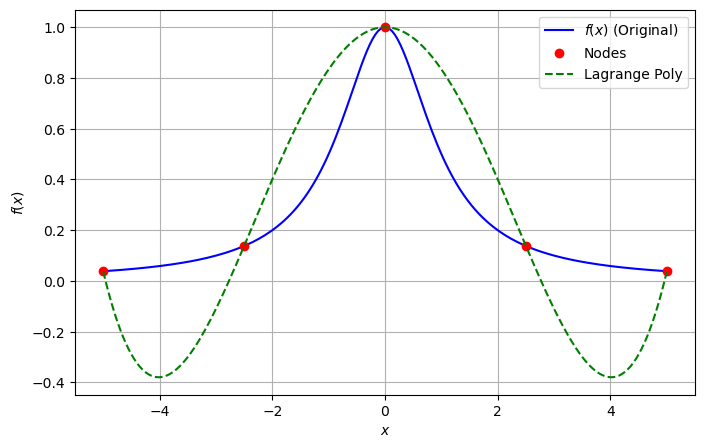

Lagrange Poly at x=1 is 0.8342175066312998
Lagrange Poly at x=4.5 is -0.2891246684350133


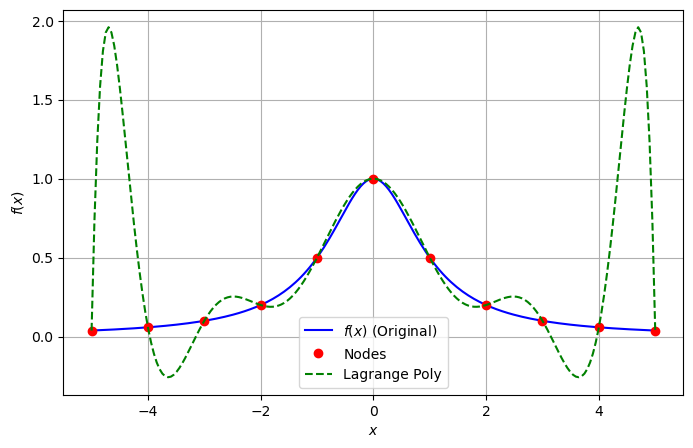

Lagrange Poly at x=1 is 0.5
Lagrange Poly at x=4.5 is 1.578720990349265


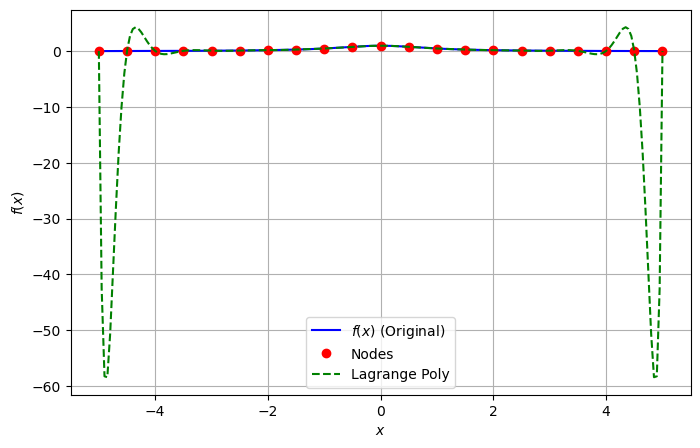

Lagrange Poly at x=1 is 0.5
Lagrange Poly at x=4.5 is 0.047058823529411764


In [106]:
def lagrange_interp(x, nodes, values):
    p_m = np.zeros_like(x, dtype=float) 
    for k in range(len(nodes)): 
            p_m += values[k]*lagrange(k, x, nodes)
    return p_m

def f(x):
    return 1/(1+x**2)

for m in [3,5,11,21]:
    nodes = np.linspace(-5, 5, m)
    values = f(nodes)
    x_val = np.linspace(-5, 5, 200)

    plt.figure(figsize=(8, 5))
    plt.plot(x_val, f(x_val), 'b-', label='$f(x)$ (Original)')
    plt.plot(nodes, values, 'ro', label='Nodes')

    plt.plot(x_val, lagrange_interp(x_val, nodes, values), 'g--', label='Lagrange Poly')

    plt.grid(True)
    plt.xlabel('$x$')
    plt.ylabel('$f(x)$')
    plt.legend() 
    plt.show()
    print('Lagrange Poly at x=1 is',lagrange_interp(1, nodes, values))
    print('Lagrange Poly at x=4.5 is',lagrange_interp(4.5, nodes, values))

Near $x=1$, the approximation actually gets better as $m$ increases. The polynomial "settles" onto the true curve in the middle of the interval.
Near $x=4.5$, the approximation fails spectacularly as $m$ grows. This is the Runge Phenomenon. 
Weierstrass guarantees that a polynomial exists, but it doesn't say that Lagrange interpolation with equidistant nodes is the way to find it. That is why Lagrange poly in this case fails to approximate f for large m.